# Importación de librerias y configuracion de semillas

## Importación de librerias 

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import gymnasium as gym


## Configuración y Semillas de reproducibilidad

In [13]:
seed = 42 #Referencia a La Guía del Autoestopista Galáctico de Douglas Adams
np.random.seed(seed)

#hiperparámetros
alpha = 0.1 #tasa de aprendizaje
gamma = 0.9 #factor de descuento
Epsilon_start = 1.0 #probabilidad de exploración inicial
Epsilon_min = 0.1 #probabilidad de exploración mínima
Epsilon_decay = 0.99 #factor de decaimiento de la probabilidad de

episodes = 2000 #número de episodios
max_steps = 100 #número máximo de pasos por episodio


# Inicializacion de entornos y tabla Q

In [14]:
#usamos el entorno de FrozenLake-v1 con mapas predefinidos o deterministic/slippery

env = gym.make('FrozenLake-v1', is_slippery=False, render_mode='rgb_array') #is_slippery=False para un entorno determinista
env.action_space.seed(seed)

num_states = env.observation_space.n
num_actions = env.action_space.n

#inicializar  la tabla Q con ceros
Q_table = np.zeros((num_states, num_actions))

#arrays para metricas  de desempeño 
rewards_per_episode = []
steps_per_episode = []


# Politicas  Elipson-Greedy

In [15]:
def choose_action(state, epsilon, env, q_table):
    """
    Selecciona una acción utilizando la política Epsilon-Greedy.
    
    Args:
        state (int): Estado actual del agente.
        epsilon (float): Probabilidad actual de exploración.
        env (gym.Env): Entorno de Gymnasium/Gym.
        q_table (np.ndarray): Matriz Q del agente.
        
    Returns:
        int: Acción elegida.
    """
    if np.random.uniform(0, 1) < epsilon:
        return env.action_space.sample()  # Exploración
    else:
        # Explotación: romper empates aleatoriamente
        max_q = np.max(q_table[state, :])
        actions_with_max_q = np.where(q_table[state, :] == max_q)[0]
        return np.random.choice(actions_with_max_q)

# Bucle de entrnamiento (Q-Learning)

In [20]:
epsilon = Epsilon_start

for episode in range(episodes):
    state, _ = env.reset(seed=seed)
    total_reward = 0
    steps = 0
    
    for step in range(max_steps):
        action = choose_action(state, epsilon, env, Q_table)
        next_state, reward, terminated, truncated, _ = env.step(action)
        
        # Actualizar la tabla Q usando la ecuación de Bellman
        best_next_action = np.argmax(Q_table[next_state, :])
        td_target = reward + gamma * Q_table[next_state, best_next_action]
        td_delta = td_target - Q_table[state, action]
        Q_table[state, action] += alpha * td_delta
        
        state = next_state
        total_reward += reward
        steps += 1
        
        if terminated or truncated:
            break
        
        rewards_per_episode.append(total_reward)
        steps_per_episode.append(steps)
        
        # Decaimiento de epsilon
        epsilon = max(Epsilon_min, epsilon * Epsilon_decay)
        next_state, reward, terminated, truncated, _ = env.step(action)
        
        # Actualizar la tabla Q usando la ecuación de Bellman
        best_next_action = np.argmax(Q_table[next_state, :])
        td_target = reward + gamma * Q_table[next_state, best_next_action]
        td_delta = td_target - Q_table[state, action]
        Q_table[state, action] += alpha * td_delta
        
        state = next_state
        total_reward += reward
        steps += 1
        
        if terminated or truncated:
            break
    
    rewards_per_episode.append(total_reward)
    steps_per_episode.append(steps)
    
    # Decaimiento de epsilon
    epsilon = max(Epsilon_min, epsilon * Epsilon_decay)
    rewards_per_episode.append(total_reward)
    steps_per_episode.append(step + 1)
print("Entrenamiento completado.")

Entrenamiento completado.


# Visualización y metricas 

## Promedio móvil para suavizar la curva de aprendizaje

In [21]:
window_size = 50
moving_avg_rewards = np.convolve(rewards_per_episode, np.ones(window_size)/window_size, mode='valid')

plt.figure(figsize=(14, 5))

<Figure size 1400x500 with 0 Axes>

<Figure size 1400x500 with 0 Axes>

## Gráfico 1: Recompensa Acumulada

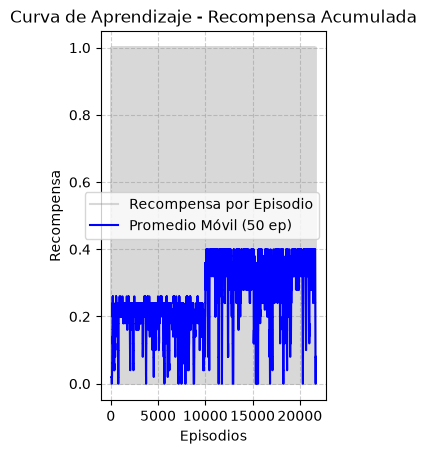

In [23]:
plt.subplot(1, 2, 1)
plt.plot(rewards_per_episode, alpha=0.3, color='gray', label='Recompensa por Episodio')
plt.plot(range(window_size - 1, len(rewards_per_episode)), moving_avg_rewards,
         color='blue', label=f'Promedio Móvil ({window_size} ep)')
plt.title('Curva de Aprendizaje - Recompensa Acumulada')
plt.xlabel('Episodios')
plt.ylabel('Recompensa')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

# Gráfico 2: Heatmap de los Valores V(s) Aprendidos

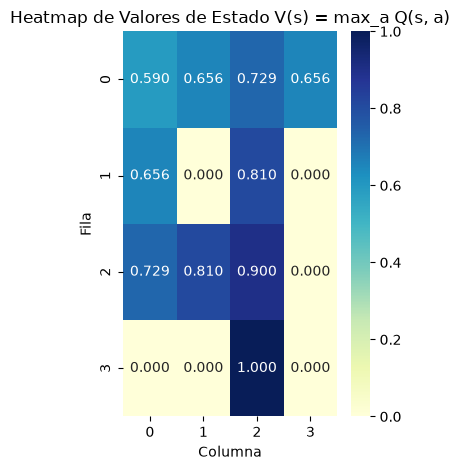

In [24]:
plt.subplot(1, 2, 2)
state_values = np.max(Q_table, axis=1).reshape((4, 4))
sns.heatmap(state_values, annot=True, fmt=".3f", cmap="YlGnBu", cbar=True)
plt.title('Heatmap de Valores de Estado V(s) = max_a Q(s, a)')
plt.xlabel('Columna')
plt.ylabel('Fila')

plt.tight_layout()
plt.show()

## Resumen de Métricas

In [25]:
tasa_exito = (sum(rewards_per_episode[-100:]) / 100) * 100
print(f"\n--- MÉTRICAS FINALES ---")
print(f"Tasa de éxito en los últimos 100 episodios: {tasa_exito:.2f}%")
print(f"Valor Q máximo registrado: {np.max(Q_table):.4f}")


--- MÉTRICAS FINALES ---
Tasa de éxito en los últimos 100 episodios: 14.00%
Valor Q máximo registrado: 1.0000
